Error RMS 2.0918122642864043
Punto:  0
Error local %:  4.218847493575595e-13
Punto:  1
Error local %:  -0.5677272792031219
Punto:  2
Error local %:  -0.5283477801932256
Punto:  3
Error local %:  -0.4934687953551162
Punto:  4
Error local %:  -0.4623605115803772
Punto:  5
Error local %:  -0.4344428210140139
Punto:  6
Error local %:  -0.4092488075757464
Punto:  7
Error local %:  -0.38639842329469176
Punto:  8
Error local %:  -0.36557918428282093
Punto:  9
Error local %:  -0.34653179539962
Punto:  10
Error local %:  -0.3290392954049487
Punto:  11
Error local %:  -0.3129187561940849
Punto:  12
Error local %:  -0.2980148614520991
Punto:  13
Error local %:  -0.2841948863276069
Punto:  14
Error local %:  -0.27134473401894765
Punto:  15
Error local %:  -0.2593657784769335
Punto:  16
Error local %:  -0.24817232821622565
Punto:  17
Error local %:  -0.23768957321045212
Punto:  18
Error local %:  -0.22785191082014114
Punto:  19
Error local %:  -0.21860157155810964
Punto:  20
Error local %:  -0.2098

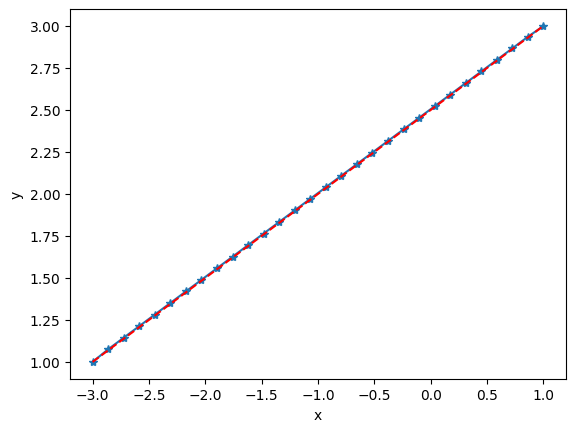

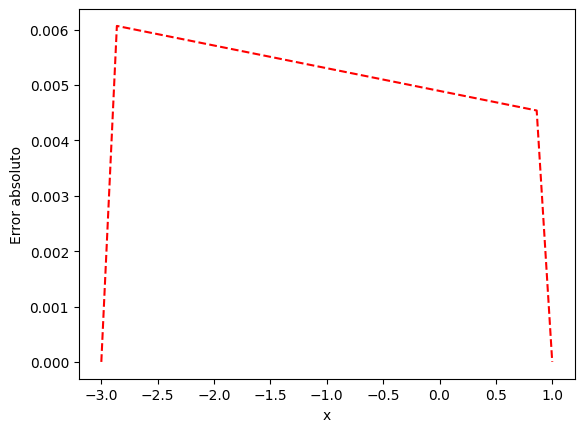

In [1]:
#Se importan las libreráis
import numpy as np
import matplotlib.pyplot as plt

#Se definen los parámetros
numpun=30 #número de nodos
L=1.0 #Límite derecho
xa=-3
esppun=L/(numpun-1) #Espacio entre puntos
x=np.linspace(xa,L,numpun) #Límites en x
y0=1 #Valor en y del primer punto
y2=3 #Valor en y del segundo punto

#Se generan las matrices y vectores necesarios
mcfbr=np.zeros((numpun,numpun))#Matriz que contiene la FBR
mcdfbr=np.zeros((numpun,numpun))#Matriz que contiene la FBR y sus derivadas
alfas=np.zeros(numpun)#Vector que contiene los alfas
vcons=np.zeros(numpun)#Vector que contiene los valores constantes conocidos
vsolnum= np.zeros(numpun) #Vector que contiene los resultados de la solución numérico
vsolexac= np.zeros(numpun) #Vector que contiene los resultados de la solución analítica

#Se crean las FBR y sus derivadas
def fbr (x, xepsi):
    r=((x-xepsi)**2)**(1.0/2.0)
    y= r**3
    return y

def dfbr(x,xepsi): #Derivada 1
    r=((x-xepsi)**2)**(1.0/2.0)
    y=(3*r)*(x-xepsi)
    return y

def d2fbr(x,xepsi): #Derivada 2
    r=((x-xepsi)**2)**(1.0/2.0)
    y=6*r
    return y

def solexact(x): #Función solución exacta
    y = ((y2-y0)/(L-xa))*x+(y0-((y2-y0)/(L-xa))*xa)
    return y

#Se genera un ciclo for anidado para rellenar la matriz mcdfbr y el vector de constantes conocidas
for i in range (numpun):
    if i==0:
        for j in range (numpun):
            mcdfbr [i,j]=fbr(x[i],x[j])
        vcons[i]=y0
    if i>0 and i <numpun-1:
        for j in range (numpun):
            mcdfbr[i,j]= d2fbr(x[i],x[j])
        vcons[i]=0
    if i==numpun-1:
        for j in range (numpun):
            mcdfbr [i,j]=fbr(x[i],x[j])
        vcons[i]=y2

# Se crea un for anidado para rellenar la matriz mcfbr
for i in range (numpun):
    for j in range(numpun):
        mcfbr[i,j]= fbr(x[i],x[j])


alfas= np.linalg.solve(mcdfbr,vcons)#Se rellena el vector de alfas al solucionar la matriz de mcdfbr con el vectro vcons
vsolnum= np.matmul(mcfbr,alfas)#Se rellena el vector de la solución numérica al multiplicar el mcfbr con el vector de los alfas

#Cálculo del error RMS
ErrorRMS= np.sqrt(np.sum((vsolnum-vsolexac)**2)/len(vsolexac))
print ('Error RMS', ErrorRMS)

#Se rellena el vector de solución exactas con un ciclo for
for i in range (numpun):
    vsolexac[i]= solexact(x[i])

#Cálculo de error local
for i in range (numpun):
    Errorlocal=((vsolexac[i]-vsolnum[i])/vsolexac[i])*100
    print ('Punto: ', i)
    print ('Error local %: ',Errorlocal)

#Muestra el vector de los alfas encontrados
print ('Alfas encontrados\n', alfas)

#Muestra el vector de valores exactos y numéricos
print ('Soluciones exactas\n',vsolexac)
print ('Soluciones numéricas\n',vsolnum)



#Se generan las gráficas
plt.figure(1)#Gráfica comparativa entre valores de solnum y solexac
plt.plot(x,vsolnum,'*-')
plt.plot(x,vsolexac,'--r')
plt.xlabel('x')
plt.ylabel('y')

plt.figure(2)#Gráfica que mide el error absoluto
plt.plot(x,np.abs(vsolnum-vsolexac),'--r')
plt.xlabel('x')
plt.ylabel('Error absoluto')

plt.rcParams['figure.figsize']=(9,9)
plt.show()

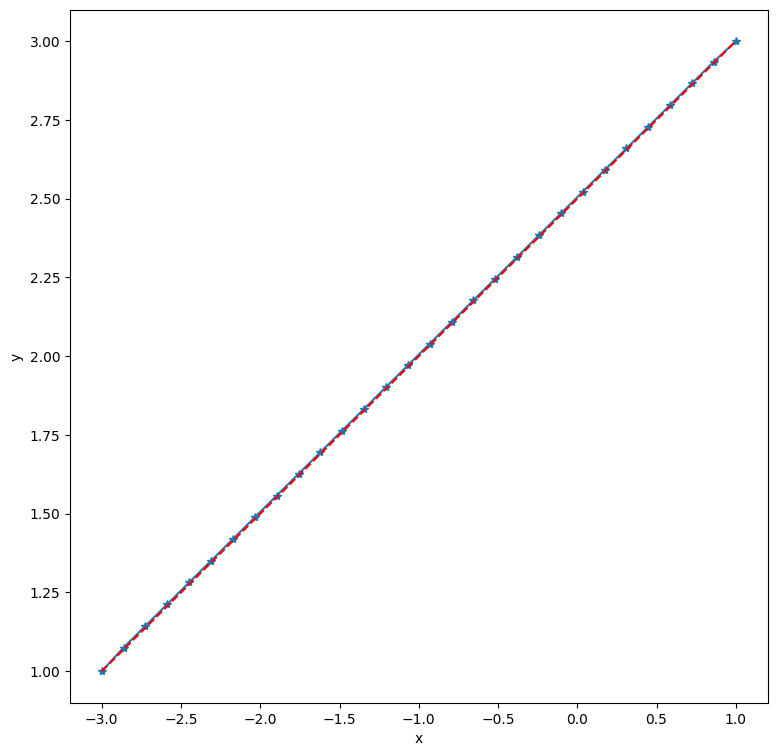

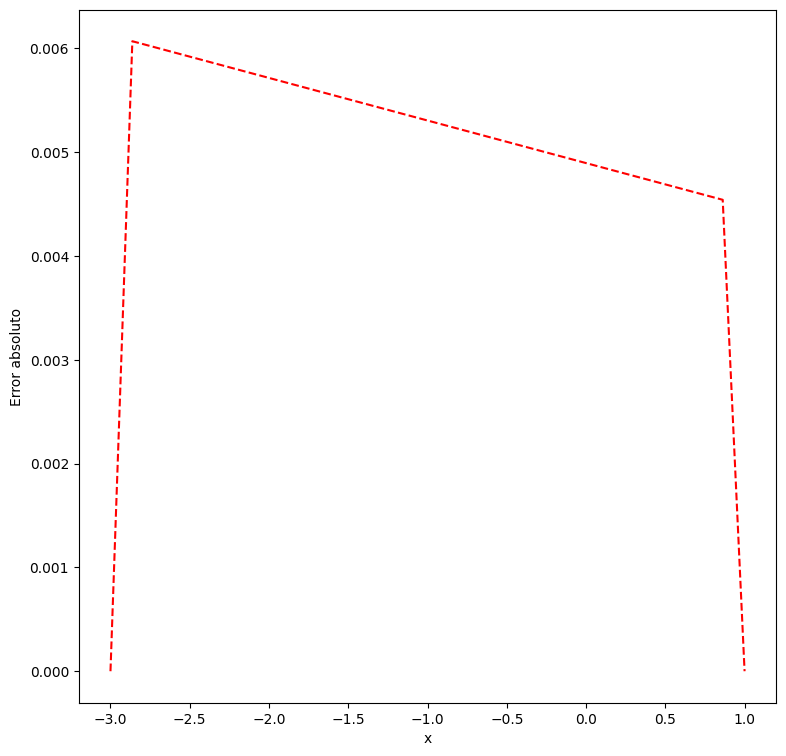

In [11]:
"""
Este script resuelve una ecuación diferencial de segundo orden utilizando el método de elementos finitos.
La ecuación diferencial es de la forma y''(x) = f(x), donde f(x) es una función dada.
El script utiliza la función f(x) para construir una matriz F y luego resuelve el sistema de ecuaciones
F * alphas = constants para obtener los valores de alphas.
Luego, utiliza los valores de alphas para calcular la solución numérica de la ecuación diferencial y
la solución exacta de la ecuación diferencial. Finalmente, grafica ambas soluciones en una sola figura.
"""

#importaciones iniciales
import numpy as np
import matplotlib.pyplot as plt

#Declaracion de variables
n, L, a = 30, 1.0, -3
x_vals = np.linspace(a, L, n)
y0, y2 = 1, 3

F, F_ddx, alphas, constants, numeric_sol, exact_sol = np.zeros((n, n)), np.zeros((n, n)), np.zeros(n), np.zeros(n), np.zeros(n), np.zeros(n)

def f(x, eps):
    """
    Devuelve el valor de la función f(x, eps) = ((x - eps) ** 2) ** 0.5) ** 3.

    Parámetros:
    x (flotante): el valor de entrada para la función.
    eps (flotante): un valor constante utilizado en la función.

    Devoluciones:
    float: El valor de la función f(x, eps).
    """
    r = ((x - eps) ** 2) ** 0.5
    return r ** 3

def df(x, eps):
    """
    Devuelve el valor de la derivada de la función f(x, eps) = ((x - eps) ** 2) ** 0.5) ** 3.

    Parámetros:
    x (flotante): el valor de entrada para la función.
    eps (flotante): un valor constante utilizado en la función.

    Devoluciones:
    float: El valor de la derivada de la función f(x, eps).
    """
    r = ((x - eps) ** 2) ** 0.5
    return 3 * r * (x - eps)

def d2f(x, eps):
    """
    Devuelve el valor de la segunda derivada de la función f(x, eps) = ((x - eps) ** 2) ** 0.5) ** 3.

    Parámetros:
    x (flotante): el valor de entrada para la función.
    eps (flotante): un valor constante utilizado en la función.

    Devoluciones:
    float: El valor de la segunda derivada de la función f(x, eps).
    """
    r = ((x - eps) ** 2) ** 0.5
    return 6 * r

def exact(x):
    """
    Devuelve la solución exacta de la ecuación diferencial.

    Parámetros:
    x (numpy.ndarray): una matriz de valores de entrada para la función.

    Devoluciones:
    numpy.ndarray: una matriz de los valores exactos de la solución.
    """
    return ((y2 - y0) / (L - a)) * x + (y0 - ((y2 - y0) / (L - a)) * a)

for i in range(n):
    for j in range(n):
        F[i, j] = f(x_vals[i], x_vals[j])

for i in range(n):
    if i == 0:
        for j in range(n):
            F_ddx[i, j] = f(x_vals[i], x_vals[j])
        constants[i] = y0
    if 0 < i < n - 1:
        for j in range(n):
            F_ddx[i, j] = d2f(x_vals[i], x_vals[j])
        constants[i] = 0
    if i == n - 1:
        for j in range(n):
            F_ddx[i, j] = f(x_vals[i], x_vals[j])
        constants[i] = y2

alphas = np.linalg.solve(F_ddx, constants)
numeric_sol = np.matmul(F, alphas)

exact_sol = exact(x_vals)

#Se generan las gráficas
plt.figure(1)#Gráficac
plt.plot(x,vsolnum,'*-')
plt.plot(x,vsolexac,'--r')
plt.xlabel('x')
plt.ylabel('y')

plt.figure(2)#Gráfica que mide el error absoluto
plt.plot(x,np.abs(vsolnum-vsolexac),'--r')
plt.xlabel('x')
plt.ylabel('Error absoluto')

plt.rcParams['figure.figsize']=(9,9)
plt.show()
